# TCGA-BRCA prognostic associations of the eight model-prioritised genes

This notebook reports the age- and pathological-stage-adjusted PFI and DSS associations of the eight model-prioritised genes (H3C14, KIAA2012, MYEOV, TMPRSS4, ZNF549, GDAP1, RUNDC3B and ZNF205) in TCGA-BRCA, shown in thesis Table 4.21 and Figure 4.20. This is external gene-level prognostic context, not validation of metastatic-phenotype classification.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
import sys
import json
import re
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from statsmodels.stats.multitest import multipletests
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    load_tcga_gene_cohort,
    fit_frozen_family_gene_cox,
)
from scripts.OligoPolyThesis import utils_ml_oligopoly as u

## Statistical methods

The analysis uses primary tumour samples, with one lexicographically selected sample per patient, the existing CDR endpoint definitions and positive follow-up eligibility. Supplied log2(TPM + 0.001) is standardized using endpoint-specific sample SD. Unpenalized continuous Cox models use Wald intervals and rank-time PH diagnostics. Adjusted PFI includes age and categorical stage I–IV, with the established step size 0.25. BH correction is applied separately to the eight tests of each endpoint. PFI and DSS are disease-related event endpoints, not interchangeable with overall mortality.

## Eight-gene age- and pathological-stage-adjusted PFI sensitivity analysis

The frozen eight-gene family is analysed using the TCGA expression source, primary-tumour sample selection, PFI eligibility and unpenalized Cox procedure described above. Each model includes one continuous gene-expression variable standardized within the adjusted cohort (sample SD), continuous age and categorical pathological stage I–IV. The complete-case cohort contains 1,053 patients and 136 PFI events. BH correction applies separately to these eight gene-expression tests.

No gene meets BH q < 0.05. Rank-time proportional-hazards diagnostics flag the expression term for ZNF549, GDAP1 and RUNDC3B at nominal p < 0.05, so a constant hazard-ratio interpretation for these genes requires caution. These are exploratory prognostic associations; covariate adjustment does not establish causality or externally validate the OMD/PMD classifier.


In [ ]:
RUN_MAIN8_ADJUSTED_PFI = False
main8_output = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/TCGA-BRCA-Prognostic-Relevance/main8')  # TCGA results for the eight model-prioritised genes
main8_symbols = ['H3C14', 'KIAA2012', 'MYEOV', 'TMPRSS4', 'ZNF549', 'GDAP1', 'RUNDC3B', 'ZNF205']
if RUN_MAIN8_ADJUSTED_PFI:
    main8_genes = pd.read_csv(Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8/harmonised_only_main8_manifest.csv')).set_index('gene_symbol').loc[main8_symbols].reset_index()
    tcga_source = Path('/mnt/data3/MCPP-Breast/External-Data/TCGA')
    main8_cohort, _ = load_tcga_gene_cohort(tcga_source / 'tcga_RSEM_gene_tpm.gz', tcga_source / 'Survival_SupplementalTable_S1_20171025_xena_sp', main8_genes)
    main8_adjusted = fit_frozen_family_gene_cox(main8_cohort, main8_genes, endpoint='PFI', adjusted=True)
    main8_adjusted['BH_family_size'] = 8
    main8_adjusted.to_csv(main8_output / 'tcga_main8_PFI_adjusted_cox.csv', index=False)
else:
    main8_adjusted = pd.read_csv(main8_output / 'tcga_main8_PFI_adjusted_cox.csv')
assert main8_adjusted.gene_symbol.tolist() == main8_symbols
assert main8_adjusted.N.eq(1053).all() and main8_adjusted.events.eq(136).all()
main8_columns = ['gene_symbol', 'N', 'events', 'HR_per_1SD', 'CI_lower', 'CI_upper', 'p_value', 'q_value', 'PH_assumption_p', 'PH_violation_flag', 'BH_family_size']
display(main8_adjusted[main8_columns].style.format({'HR_per_1SD': '{:.3f}', 'CI_lower': '{:.3f}', 'CI_upper': '{:.3f}', 'p_value': '{:.3g}', 'q_value': '{:.3g}', 'PH_assumption_p': '{:.3g}'}))


gene_symbol,N,events,HR_per_1SD,CI_lower,CI_upper,p_value,q_value,PH_assumption_p,PH_violation_flag,BH_family_size
H3C14,1053,136,1.062,0.892,1.264,0.498,0.796,0.963,False,8
KIAA2012,1053,136,0.875,0.735,1.041,0.131,0.35,0.859,False,8
MYEOV,1053,136,0.912,0.769,1.082,0.291,0.582,0.164,False,8
TMPRSS4,1053,136,0.991,0.829,1.184,0.917,0.935,0.739,False,8
ZNF549,1053,136,1.029,0.857,1.236,0.759,0.935,0.00682,True,8
GDAP1,1053,136,0.779,0.645,0.941,0.00947,0.0758,0.000102,True,8
RUNDC3B,1053,136,0.850,0.722,1.001,0.0515,0.206,0.000554,True,8
ZNF205,1053,136,1.007,0.855,1.185,0.935,0.935,0.541,False,8


## Final eight-gene age/stage-adjusted PFI and DSS associations (Table 4.21)

The verified eight-gene adjusted PFI results are reused; DSS is fitted only if its separate result file is absent. Each endpoint uses valid binary status, finite positive time, finite continuous age and recognised pathological stage (I–IV under the existing collapse). Expression uses the same supplied TCGA values and is standardized within the endpoint-specific complete-case cohort using sample SD (`ddof=1`). Each unpenalized model has formula `expression_z + age + C(stage)`. Only the expression coefficient is reported; BH correction is separate across eight tests per endpoint. The existing rank-time proportional-hazards diagnostic flags the expression term at p < 0.05; it is not a global test of all covariates. Adjustment does not establish causality or validate the OMD/PMD classifier.

The existing PFI output is not modified; the DSS and combined tables are saved separately. These cells use the imports and project root established in the first code cell.


In [1]:
GENES = ['H3C14','KIAA2012','MYEOV','TMPRSS4','ZNF549','GDAP1','RUNDC3B','ZNF205']
OUT = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/TCGA-BRCA-Prognostic-Relevance/main8')
PFI_PATH = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/TCGA-BRCA-Prognostic-Relevance/main8/tcga_main8_PFI_adjusted_cox.csv')
MANIFEST = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8/harmonised_only_main8_manifest.csv')
EXPR = Path('/mnt/data3/MCPP-Breast/External-Data/TCGA/tcga_RSEM_gene_tpm.gz')
CDR = EXPR.parent / 'Survival_SupplementalTable_S1_20171025_xena_sp'
pfi = pd.read_csv(PFI_PATH)
assert pfi.gene_symbol.tolist() == GENES and pfi.N.eq(1053).all() and pfi.events.eq(136).all()
assert pfi.adjusted.all() and pfi.BH_family_size.eq(8).all()
np.testing.assert_allclose(pfi.q_value, multipletests(pfi.p_value, method='fdr_bh')[1], rtol=1e-12, atol=1e-15)
for gene, expected in {'GDAP1':[.779,.645,.941,.00947,.0758], 'RUNDC3B':[.850,.722,1.001,.0515,.206]}.items():
    row = pfi.set_index('gene_symbol').loc[gene]
    observed = [float(f'{row.HR_per_1SD:.3f}'),float(f'{row.CI_lower:.3f}'),float(f'{row.CI_upper:.3f}'),float(f'{row.p_value:.3g}'),float(f'{row.q_value:.3g}')]
    assert observed == expected, (gene, observed)
OUT.mkdir(parents=True, exist_ok=True)
DSS_PATH = OUT / 'tcga_main8_DSS_adjusted_cox.csv'
if DSS_PATH.exists():
    dss = pd.read_csv(DSS_PATH)
else:
    genes = pd.read_csv(MANIFEST).set_index('gene_symbol').loc[GENES].reset_index()
    cohort, _ = u.load_tcga_gene_cohort(EXPR, CDR, genes)
    data = u.endpoint_cohort(cohort, 'DSS', adjusted=True)
    dss = u.fit_frozen_family_gene_cox(cohort, genes, endpoint='DSS', adjusted=True)
    dss['BH_family_size'] = 8
    assert dss.N.eq(len(data)).all() and dss.events.eq(int(data.DSS.sum())).all()
    dss.to_csv(DSS_PATH, index=False)
    report = {'formula':'expression_z + age + C(stage)', 'endpoint':'DSS / DSS.time', 'N':len(data), 'events':int(data.DSS.sum()), 'stage_counts':data.stage.value_counts().to_dict(), 'standardization':'endpoint-specific complete-case mean and sample SD ddof=1', 'PH':'rank-time expression_z term, nominal p<0.05', 'BH_family_size':8, 'expression_source':str(EXPR), 'clinical_source':str(CDR), 'manifest':str(MANIFEST), 'helper':'scripts/OligoPolyThesis/utils_ml_oligopoly.py:fit_frozen_family_gene_cox', 'PFI_reused':str(PFI_PATH)}
    (OUT / 'tcga_main8_PFI_DSS_adjusted_provenance.json').write_text(json.dumps(report, indent=2))
assert dss.gene_symbol.tolist() == GENES and dss.adjusted.all() and dss.endpoint.eq('DSS').all() and dss.BH_family_size.eq(8).all()
np.testing.assert_allclose(dss.q_value, multipletests(dss.p_value, method='fdr_bh')[1], rtol=1e-12, atol=1e-15)
combined = pd.concat([pfi, dss], ignore_index=True)
combined.to_csv(OUT / 'tcga_main8_PFI_DSS_adjusted_full_precision.csv', index=False)
print(combined[['gene_symbol','endpoint','N','events','HR_per_1SD','CI_lower','CI_upper','p_value','q_value','PH_assumption_p','PH_violation_flag']].to_string(index=False))


gene_symbol endpoint    N  events  HR_per_1SD  CI_lower  CI_upper  p_value  q_value  PH_assumption_p  PH_violation_flag
      H3C14      PFI 1053     136    1.062083  0.892423  1.263998 0.497593 0.796149         0.962732              False
   KIAA2012      PFI 1053     136    0.874665  0.735018  1.040843 0.131322 0.350192         0.859498              False
      MYEOV      PFI 1053     136    0.912334  0.769445  1.081759 0.291106 0.582212         0.164307              False
    TMPRSS4      PFI 1053     136    0.990572  0.828783  1.183946 0.917083 0.935207         0.739499              False
     ZNF549      PFI 1053     136    1.029199  0.856678  1.236462 0.758503 0.935207         0.006822               True
      GDAP1      PFI 1053     136    0.779164  0.645300  0.940797 0.009473 0.075786         0.000102               True
    RUNDC3B      PFI 1053     136    0.850045  0.721811  1.001061 0.051505 0.206019         0.000554               True
     ZNF205      PFI 1053     136    1.0

In [2]:
table421 = pd.DataFrame({'Gene': GENES})
for endpoint, results in [('PFI', pfi), ('DSS', dss)]:
    table421[f'{endpoint} HR (95% CI)'] = [f'{r.HR_per_1SD:.3f} ({r.CI_lower:.3f}–{r.CI_upper:.3f})' for r in results.itertuples()]
    table421[f'{endpoint} BH q-value'] = results.q_value.map(lambda v: f'{v:.3g}').to_numpy()
table421.to_csv(OUT / 'table_4_21_thesis_ready.csv', index=False)
display(table421)
for endpoint, results in [('PFI', pfi), ('DSS', dss)]:
    print(endpoint, 'N =', results.N.unique().tolist(), 'events =', results.events.unique().tolist(),
          'BH q < 0.05:', results.loc[results.q_value.lt(.05), 'gene_symbol'].tolist(),
          'expression PH p < 0.05:', results.loc[results.PH_assumption_p.lt(.05), 'gene_symbol'].tolist())


,Gene,PFI HR (95% CI),PFI BH q-value,DSS HR (95% CI),DSS BH q-value
0,H3C14,1.062 (0.892–1.264),0.796,1.048 (0.829–1.327),0.741
1,KIAA2012,0.875 (0.735–1.041),0.35,0.807 (0.641–1.016),0.272
2,MYEOV,0.912 (0.769–1.082),0.582,0.953 (0.755–1.203),0.741
3,TMPRSS4,0.991 (0.829–1.184),0.935,1.171 (0.911–1.504),0.569
4,ZNF549,1.029 (0.857–1.236),0.935,1.043 (0.814–1.336),0.741
5,GDAP1,0.779 (0.645–0.941),0.0758,0.768 (0.601–0.981),0.272
6,RUNDC3B,0.850 (0.722–1.001),0.206,0.954 (0.757–1.201),0.741
7,ZNF205,1.007 (0.855–1.185),0.935,0.896 (0.732–1.096),0.569


PFI N = [1053] events = [136] BH q < 0.05: [] expression PH p < 0.05: ['ZNF549', 'GDAP1', 'RUNDC3B']
DSS N = [1036] events = [79] BH q < 0.05: [] expression PH p < 0.05: ['GDAP1', 'RUNDC3B']


## Figure 4.20 | Adjusted PFI and DSS forest plots

These plots read the exact displayed HRs and 95% confidence limits from the final Table 4.21 CSV (three-decimal estimates), rather than refitting models. They show gene-expression associations adjusted for continuous age and categorical pathological stage, with matching logarithmic axes. All points use the same colour: no gene passes endpoint-specific BH correction across eight tests. A confidence interval excluding 1 does not imply BH-adjusted significance. The expression-term PH flags documented above still apply. Exports are saved under `figures/results/biological_interpretation/`.


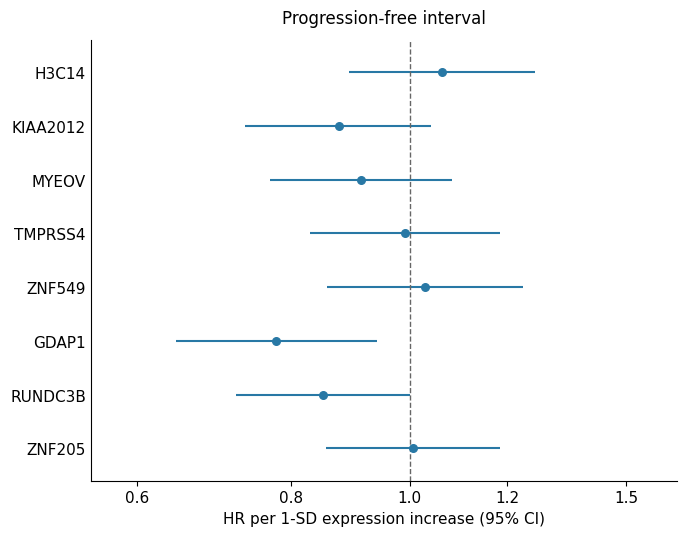

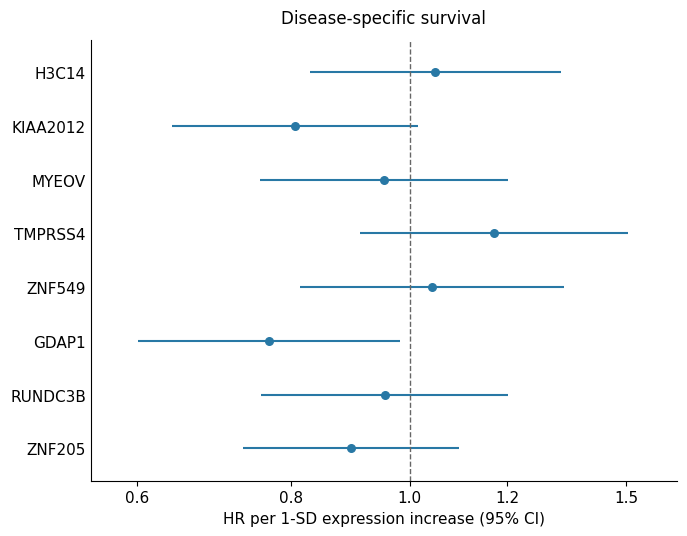

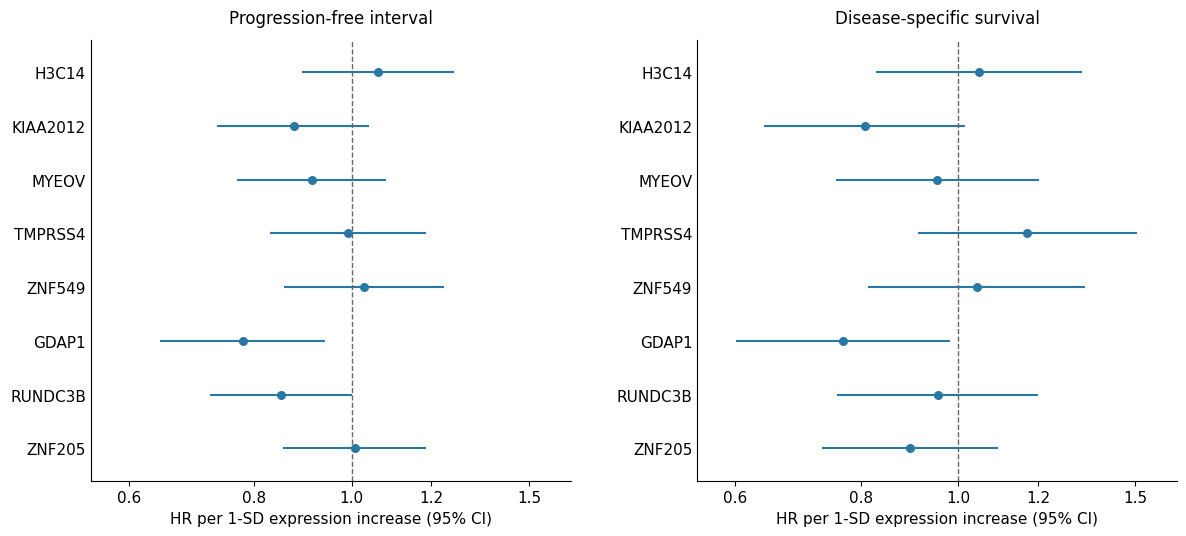

Verified: all 16 plotted HRs and 32 CI limits exactly match Table 4.21 display values. No models fitted.


In [1]:
FIG423_SOURCE = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/TCGA-BRCA-Prognostic-Relevance/main8/table_4_21_thesis_ready.csv')
FIG423_OUT = ROOT / 'figures/results/biological_interpretation'
fig423_table = pd.read_csv(FIG423_SOURCE, dtype=str)
fig423_genes = ['H3C14','KIAA2012','MYEOV','TMPRSS4','ZNF549','GDAP1','RUNDC3B','ZNF205']
assert fig423_table.Gene.tolist() == fig423_genes
fig423_values = {}
for endpoint in ['PFI', 'DSS']:
    parsed = []
    for text in fig423_table[f'{endpoint} HR (95% CI)']:
        match = re.fullmatch(r'(\d+\.\d+) \((\d+\.\d+)–(\d+\.\d+)\)', text)
        assert match, text
        hr, low, high = map(float, match.groups())
        assert 0 < low <= hr <= high
        assert f'{hr:.3f} ({low:.3f}–{high:.3f})' == text
        parsed.append([hr, low, high])
    fig423_values[endpoint] = np.array(parsed)
    assert pd.to_numeric(fig423_table[f'{endpoint} BH q-value']).ge(.05).all()

# No significance-dependent colour, marker, or annotation.
def plot_fig423_endpoint(ax, endpoint, title):
    values = fig423_values[endpoint]
    y = np.arange(len(fig423_genes))
    ax.hlines(y, values[:, 1], values[:, 2], color='#2878a5', linewidth=1.5)
    ax.scatter(values[:, 0], y, color='#2878a5', s=30, zorder=3)
    ax.axvline(1, color='#666666', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_xlim(.55, 1.65)
    ax.xaxis.set_major_locator(FixedLocator([.6, .8, 1., 1.2, 1.5]))
    ax.xaxis.set_major_formatter(FixedFormatter(['0.6','0.8','1.0','1.2','1.5']))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_yticks(y, fig423_genes)
    ax.set_ylim(7.6, -.6)
    ax.set_xlabel('HR per 1-SD expression increase (95% CI)')
    ax.set_title(title, fontsize=12, pad=12)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', length=0)

FIG423_OUT.mkdir(parents=True, exist_ok=True)
with plt.rc_context({'font.family':'DejaVu Sans', 'font.size':11, 'pdf.fonttype':42}):
    for endpoint, title in [('PFI','Progression-free interval'), ('DSS','Disease-specific survival')]:
        fig, ax = plt.subplots(figsize=(7, 5.5))
        plot_fig423_endpoint(ax, endpoint, title)
        fig.tight_layout()
        for extension in ['png', 'pdf']:
            fig.savefig(FIG423_OUT / f'tcga_main8_{endpoint}_adjusted_forest.{extension}', dpi=350, bbox_inches='tight')
        plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
    for ax, endpoint, title in zip(axes, ['PFI','DSS'], ['Progression-free interval','Disease-specific survival']):
        plot_fig423_endpoint(ax, endpoint, title)
        ax.tick_params(axis='y', labelleft=True)
    fig.tight_layout(w_pad=3)
    for extension in ['png', 'pdf']:
        fig.savefig(FIG423_OUT / f'tcga_main8_PFI_DSS_adjusted_forest.{extension}', dpi=350, bbox_inches='tight')
    plt.show()
print('Verified: all 16 plotted HRs and 32 CI limits exactly match Table 4.21 display values. No models fitted.')
